# GoEmotions Sentiment Classification


## 1. Install Libraries

In [ ]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn joblib

In [ ]:
import re
import html
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, auc
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

## 2. Load and Validate the Dataset

In [ ]:
DATA_URL = "https://huggingface.co/datasets/mrm8488/goemotions/resolve/main/goemotions.csv"
df = pd.read_csv(DATA_URL)

print("Dataset shape:", df.shape)
print("Unique comments:", df["id"].nunique())
print("Duplicate annotation rows by comment ID:", df.duplicated("id").sum())
display(df.head())

Dataset shape: (211225, 37)
Unique comments: 58011
Duplicate annotation rows by comment ID: 153214


,text,id,author,subreddit,link_id,parent_id,created_utc,rater_id,example_very_unclear,admiration,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
0,That game hurt.,eew5j0j,Brdd9,nrl,t3_ajis4z,t1_eew18eq,1.548381e+09,1,False,0,...,0,0,0,0,0,0,0,1,0,0
1,>sexuality shouldn’t be a grouping category I...,eemcysk,TheGreen888,unpopularopinion,t3_ai4q37,t3_ai4q37,1.548084e+09,37,True,0,...,0,0,0,0,0,0,0,0,0,0
2,"You do right, if you don't care then fuck 'em!",ed2mah1,Labalool,confessions,t3_abru74,t1_ed2m7g7,1.546428e+09,37,False,0,...,0,0,0,0,0,0,0,0,0,1
3,Man I love reddit.,eeibobj,MrsRobertshaw,facepalm,t3_ahulml,t3_ahulml,1.547965e+09,18,False,0,...,1,0,0,0,0,0,0,0,0,0
4,"[NAME] was nowhere near them, he was by the Fa...",eda6yn6,American_Fascist713,starwarsspeculation,t3_ackt2f,t1_eda65q2,1.546669e+09,2,False,0,...,0,0,0,0,0,0,0,0,0,1


In [ ]:
assert df.shape[0] >= 100_000, "Dataset does not meet the 100k-record requirement."
assert df.shape[1] >= 35, "Dataset does not meet the 35-column requirement."
assert df.shape[1] == 37, "Unexpected schema; review the source file before continuing."

print("Records requirement passed:", df.shape[0])
print("Feature/column requirement passed:", df.shape[1])
print(df.dtypes)

Records requirement passed: 211225
Feature/column requirement passed: 37
text                     object
id                       object
author                   object
subreddit                object
link_id                  object
parent_id                object
created_utc             float64
rater_id                  int64
example_very_unclear       bool
admiration                int64
amusement                 int64
anger                     int64
annoyance                 int64
approval                  int64
caring                    int64
confusion                 int64
curiosity                 int64
desire                    int64
disappointment            int64
disapproval               int64
disgust                   int64
embarrassment             int64
excitement                int64
fear                      int64
gratitude                 int64
grief                     int64
joy                       int64
love                      int64
nervousness               int64

## 3. Research Validation and Model Selection



**Why Logistic Regression:** It handles sparse TF-IDF features efficiently, provides class scores/probabilities, supports regularization and is interpretable through feature weights.

**Why Linear SVM:** It is designed for high-dimensional sparse spaces and learns maximum-margin boundaries, making it a strong classical text-classification comparator.

## 4. Define Emotion Groups and Target Variable

In [ ]:
EMOTION_COLUMNS = [
    "admiration", "amusement", "anger", "annoyance", "approval", "caring",
    "confusion", "curiosity", "desire", "disappointment", "disapproval",
    "disgust", "embarrassment", "excitement", "fear", "gratitude", "grief",
    "joy", "love", "nervousness", "optimism", "pride", "realization",
    "relief", "remorse", "sadness", "surprise", "neutral"
]

POSITIVE = [
    "admiration", "amusement", "approval", "caring", "desire", "excitement",
    "gratitude", "joy", "love", "optimism", "pride", "relief"
]
NEGATIVE = [
    "anger", "annoyance", "disappointment", "disapproval", "disgust",
    "embarrassment", "fear", "grief", "nervousness", "remorse", "sadness"
]
AMBIGUOUS = ["confusion", "curiosity", "realization", "surprise"]
NEUTRAL = ["neutral"]

def create_sentiment_target(data):
    scores = np.column_stack([
        data[POSITIVE].sum(axis=1).to_numpy(),
        data[NEGATIVE].sum(axis=1).to_numpy(),
        data[AMBIGUOUS].sum(axis=1).to_numpy(),
        data[NEUTRAL].sum(axis=1).to_numpy()
    ])
    class_names = np.array(["Positive", "Negative", "Ambiguous", "Neutral"])
    maximum = scores.max(axis=1)
    valid = ((scores == maximum[:, None]).sum(axis=1) == 1) & (maximum > 0)
    result = data.loc[valid].copy()
    result["sentiment_category"] = class_names[scores[valid].argmax(axis=1)]
    return result, int((~valid).sum())

## 5. Clean the Data

In [ ]:
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    text = re.sub(r"(?:u/|@)\w+", " USER ", text)
    return re.sub(r"\s+", " ", text).strip()

df = df.loc[~df["example_very_unclear"].fillna(True)].copy()
df = df.loc[df[EMOTION_COLUMNS].sum(axis=1) > 0].copy()
df["clean_text"] = df["text"].map(clean_text)
df = df.loc[df["clean_text"].str.len() > 0].reset_index(drop=True)
df, tied_rows_removed = create_sentiment_target(df)

print("Usable records:", len(df))
print("Tied cross-group annotations removed:", tied_rows_removed)
print(df["sentiment_category"].value_counts())

Usable records: 195928
Tied cross-group annotations removed: 11886
sentiment_category
Positive     72796
Neutral      55298
Negative     46877
Ambiguous    20957
Name: count, dtype: int64


## 6. Explore the Target Distribution

,records
sentiment_category,
Positive,72796
Neutral,55298
Negative,46877
Ambiguous,20957


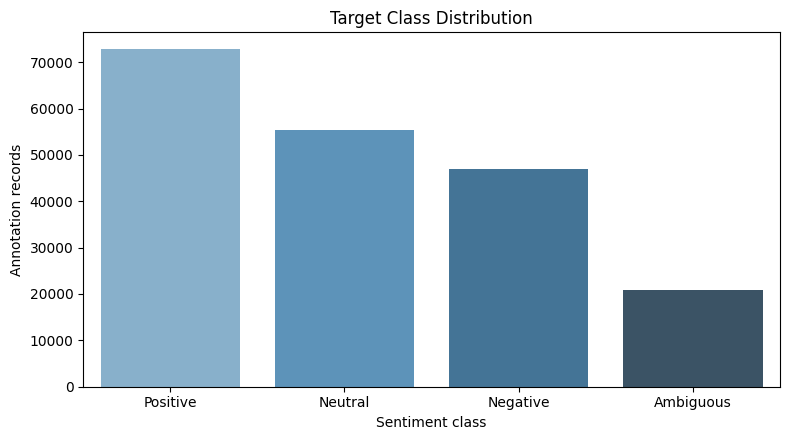

In [ ]:
target_counts = df["sentiment_category"].value_counts()
display(target_counts.to_frame("records"))

plt.figure(figsize=(8, 4.5))
sns.barplot(x=target_counts.index, y=target_counts.values, palette="Blues_d")
plt.title("Target Class Distribution")
plt.xlabel("Sentiment class")
plt.ylabel("Annotation records")
plt.tight_layout()
plt.show()

## 7. Create a Leakage-Safe 80/20 Split

In [ ]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_index, test_index = next(
    splitter.split(df, y=df["sentiment_category"], groups=df["id"])
)

train_df = df.iloc[train_index].copy()
test_df = df.iloc[test_index].copy()

print("Training rows:", len(train_df), f"({len(train_df)/len(df):.2%})")
print("Testing rows:", len(test_df), f"({len(test_df)/len(df):.2%})")
print("Train unique IDs:", train_df["id"].nunique())
print("Test unique IDs:", test_df["id"].nunique())
print("ID overlap:", len(set(train_df["id"]) & set(test_df["id"])))

Training rows: 156866 (80.06%)
Testing rows: 39062 (19.94%)
Train unique IDs: 46248
Test unique IDs: 11562
ID overlap: 0


## 8. Encode the Target and Extract TF-IDF Features

In [ ]:
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(train_df["sentiment_category"])
y_test = label_encoder.transform(test_df["sentiment_category"])

tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.98,
    max_features=60_000,
    sublinear_tf=True,
    strip_accents="unicode",
    dtype=np.float32
)

X_train = tfidf.fit_transform(train_df["clean_text"])
X_test = tfidf.transform(test_df["clean_text"])

print("Training matrix:", X_train.shape)
print("Testing matrix:", X_test.shape)
print("Class order:", label_encoder.classes_)

Training matrix: (156866, 60000)
Testing matrix: (39062, 60000)
Class order: ['Ambiguous' 'Negative' 'Neutral' 'Positive']


## 9. Train Logistic Regression

In [ ]:
lr_model = OneVsRestClassifier(
    LogisticRegression(
        C=0.25,
        max_iter=1000,
        class_weight="balanced",
        solver="liblinear",
        random_state=RANDOM_STATE
    ),
    n_jobs=1
)
lr_model.fit(X_train, y_train)

OneVsRestClassifier(estimator=LogisticRegression(C=0.25,
                                                 class_weight='balanced',
                                                 max_iter=1000, random_state=42,
                                                 solver='liblinear'),
                    n_jobs=1)

## 10. Train Linear SVM

In [ ]:
svm_model = LinearSVC(
    C=0.10,
    class_weight="balanced",
    random_state=RANDOM_STATE
)
svm_model.fit(X_train, y_train)

LinearSVC(C=0.1, class_weight='balanced', random_state=42)

## 11. Evaluate Both Models

In [ ]:
def evaluate_model(name, model, X_train, y_train, X_test, y_test):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    test_scores = (
        model.predict_proba(X_test)
        if hasattr(model, "predict_proba")
        else model.decision_function(X_test)
    )
    y_test_binary = label_binarize(y_test, classes=np.arange(len(label_encoder.classes_)))
    test_macro_f1 = f1_score(y_test, test_pred, average="macro", zero_division=0)
    train_macro_f1 = f1_score(y_train, train_pred, average="macro", zero_division=0)

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, test_pred),
        "Precision (Macro)": precision_score(y_test, test_pred, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_test, test_pred, average="macro", zero_division=0),
        "F1 (Macro)": test_macro_f1,
        "F1 (Weighted)": f1_score(y_test, test_pred, average="weighted", zero_division=0),
        "AUC-ROC (Macro OvR)": roc_auc_score(y_test_binary, test_scores, average="macro", multi_class="ovr"),
        "Train F1 (Macro)": train_macro_f1,
        "Generalization Gap": train_macro_f1 - test_macro_f1
    }
    return metrics, test_pred, test_scores

lr_metrics, lr_pred, lr_scores = evaluate_model(
    "Logistic Regression", lr_model, X_train, y_train, X_test, y_test
)
svm_metrics, svm_pred, svm_scores = evaluate_model(
    "Linear SVM", svm_model, X_train, y_train, X_test, y_test
)

comparison = pd.DataFrame([lr_metrics, svm_metrics])
display(comparison.style.format({column: "{:.4f}" for column in comparison.columns[1:]}))

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),F1 (Weighted),AUC-ROC (Macro OvR),Train F1 (Macro),Generalization Gap
0,Logistic Regression,0.5644,0.5352,0.5517,0.5381,0.5718,0.7961,0.6247,0.0866
1,Linear SVM,0.5723,0.5354,0.5493,0.5403,0.5753,0.7947,0.6749,0.1346


In [ ]:
from sklearn.metrics import classification_report

def get_class_metrics(y_true, y_pred, target_names):
    report = classification_report(y_true, y_pred, target_names=target_names, output_dict=True, zero_division=0)
    metrics_data = {}
    for class_name in target_names:
        metrics_data[class_name] = {
            'Precision': report[class_name]['precision'],
            'Recall': report[class_name]['recall'],
            'F1-Score': report[class_name]['f1-score']
        }
    return metrics_data, report['accuracy']

target_names = label_encoder.classes_
lr_class_metrics, lr_accuracy = get_class_metrics(y_test, lr_pred, target_names)
svm_class_metrics, svm_accuracy = get_class_metrics(y_test, svm_pred, target_names)


all_metrics = []
for class_name in target_names:
    all_metrics.append({
        'Metric': 'Precision',
        'Group': class_name,
        'Logistic Regression': lr_class_metrics[class_name]['Precision'],
        'Linear SVM': svm_class_metrics[class_name]['Precision']
    })
    all_metrics.append({
        'Metric': 'Recall',
        'Group': class_name,
        'Logistic Regression': lr_class_metrics[class_name]['Recall'],
        'Linear SVM': svm_class_metrics[class_name]['Recall']
    })
    all_metrics.append({
        'Metric': 'F1-Score',
        'Group': class_name,
        'Logistic Regression': lr_class_metrics[class_name]['F1-Score'],
        'Linear SVM': svm_class_metrics[class_name]['F1-Score']
    })

# Add overall accuracy
all_metrics.append({
    'Metric': 'Accuracy',
    'Group': 'Overall',
    'Logistic Regression': lr_accuracy,
    'Linear SVM': svm_accuracy
})

metrics_df = pd.DataFrame(all_metrics)
display(metrics_df.style.format(subset=['Logistic Regression', 'Linear SVM'], formatter="{:.4f}"))

,Metric,Group,Logistic Regression,Linear SVM
0,Precision,Ambiguous,0.3505,0.3692
1,Recall,Ambiguous,0.5186,0.4739
2,F1-Score,Ambiguous,0.4183,0.4150
3,Precision,Negative,0.5505,0.5529
4,Recall,Negative,0.5695,0.5876
5,F1-Score,Negative,0.5598,0.5697
6,Precision,Neutral,0.4809,0.4893
7,Recall,Neutral,0.4780,0.4533
8,F1-Score,Neutral,0.4795,0.4706
9,Precision,Positive,0.7590,0.7303


In [ ]:
unique_groups = metrics_df['Group'].unique()

for group in unique_groups:
    if group != 'Overall': # Handle overall accuracy separately if needed, or include here
        print(f"### Metrics for {group}:")
        display(metrics_df[metrics_df['Group'] == group].style.format(subset=['Logistic Regression', 'Linear SVM'], formatter="{:.4f}"))

# Display overall accuracy separately
print("### Overall Accuracy:")
display(metrics_df[metrics_df['Group'] == 'Overall'].style.format(subset=['Logistic Regression', 'Linear SVM'], formatter="{:.4f}"))

### Metrics for Ambiguous:


,Metric,Group,Logistic Regression,Linear SVM
0,Precision,Ambiguous,0.3505,0.3692
1,Recall,Ambiguous,0.5186,0.4739
2,F1-Score,Ambiguous,0.4183,0.4150


### Metrics for Negative:


,Metric,Group,Logistic Regression,Linear SVM
3,Precision,Negative,0.5505,0.5529
4,Recall,Negative,0.5695,0.5876
5,F1-Score,Negative,0.5598,0.5697


### Metrics for Neutral:


,Metric,Group,Logistic Regression,Linear SVM
6,Precision,Neutral,0.4809,0.4893
7,Recall,Neutral,0.4780,0.4533
8,F1-Score,Neutral,0.4795,0.4706


### Metrics for Positive:


,Metric,Group,Logistic Regression,Linear SVM
9,Precision,Positive,0.7590,0.7303
10,Recall,Positive,0.6408,0.6826
11,F1-Score,Positive,0.6949,0.7056


### Overall Accuracy:


,Metric,Group,Logistic Regression,Linear SVM
12,Accuracy,Overall,0.5644,0.5723


## 12. Evaluate Models for Individual Emotions (Multi-label)



In [ ]:
# Prepare multi-label targets for individual emotions
y_train_emotions = train_df[EMOTION_COLUMNS].to_numpy()
y_test_emotions = test_df[EMOTION_COLUMNS].to_numpy()

print("Training multi-label targets shape:", y_train_emotions.shape)
print("Testing multi-label targets shape:", y_test_emotions.shape)

Training multi-label targets shape: (156866, 28)
Testing multi-label targets shape: (39062, 28)


### Train Logistic Regression (Multi-label)

In [ ]:
# Re-initialize and train Logistic Regression for multi-label classification
lr_multilabel_model = OneVsRestClassifier(
    LogisticRegression(
        C=0.25, # Using the same best C from single-label
        max_iter=1000,
        class_weight="balanced", # Apply class weights per binary classifier
        solver="liblinear",
        random_state=RANDOM_STATE
    ),
    n_jobs=1
)
lr_multilabel_model.fit(X_train, y_train_emotions)

lr_multilabel_pred = lr_multilabel_model.predict(X_test)
print("Logistic Regression Multi-label training complete.")

Logistic Regression Multi-label training complete.


### Train Linear SVM (Multi-label)

In [ ]:
# Re-initialize and train Linear SVM for multi-label classification
svm_multilabel_model = OneVsRestClassifier(
    LinearSVC(
        C=0.10, # Using the same best C from single-label
        class_weight="balanced", # Apply class weights per binary classifier
        random_state=RANDOM_STATE
    ),
    n_jobs=1
)
svm_multilabel_model.fit(X_train, y_train_emotions)

svm_multilabel_pred = svm_multilabel_model.predict(X_test)
print("Linear SVM Multi-label training complete.")

Linear SVM Multi-label training complete.


### Per-Emotion Metrics Table

In [ ]:
emotion_metrics_data = []

for i, emotion_name in enumerate(EMOTION_COLUMNS):
    lr_report = classification_report(y_test_emotions[:, i], lr_multilabel_pred[:, i], output_dict=True, zero_division=0)
    svm_report = classification_report(y_test_emotions[:, i], svm_multilabel_pred[:, i], output_dict=True, zero_division=0)

    # Class '1' represents the presence of the emotion
    emotion_metrics_data.append({
        'Emotion': emotion_name,
        'Metric': 'Precision',
        'Logistic Regression': lr_report['1']['precision'],
        'Linear SVM': svm_report['1']['precision']
    })
    emotion_metrics_data.append({
        'Emotion': emotion_name,
        'Metric': 'Recall',
        'Logistic Regression': lr_report['1']['recall'],
        'Linear SVM': svm_report['1']['recall']
    })
    emotion_metrics_data.append({
        'Emotion': emotion_name,
        'Metric': 'F1-Score',
        'Logistic Regression': lr_report['1']['f1-score'],
        'Linear SVM': svm_report['1']['f1-score']
    })

emotion_metrics_df = pd.DataFrame(emotion_metrics_data)
display(emotion_metrics_df.style.format(subset=['Logistic Regression', 'Linear SVM'], formatter="{:.4f}"))

,Emotion,Metric,Logistic Regression,Linear SVM
0,admiration,Precision,0.3669,0.3814
1,admiration,Recall,0.7222,0.6958
2,admiration,F1-Score,0.4866,0.4927
3,amusement,Precision,0.4552,0.4375
4,amusement,Recall,0.7709,0.7576
5,amusement,F1-Score,0.5724,0.5547
6,anger,Precision,0.2009,0.2123
7,anger,Recall,0.5792,0.5299
8,anger,F1-Score,0.2983,0.3031
9,annoyance,Precision,0.1499,0.1559


## 12. Plot Confusion Matrices

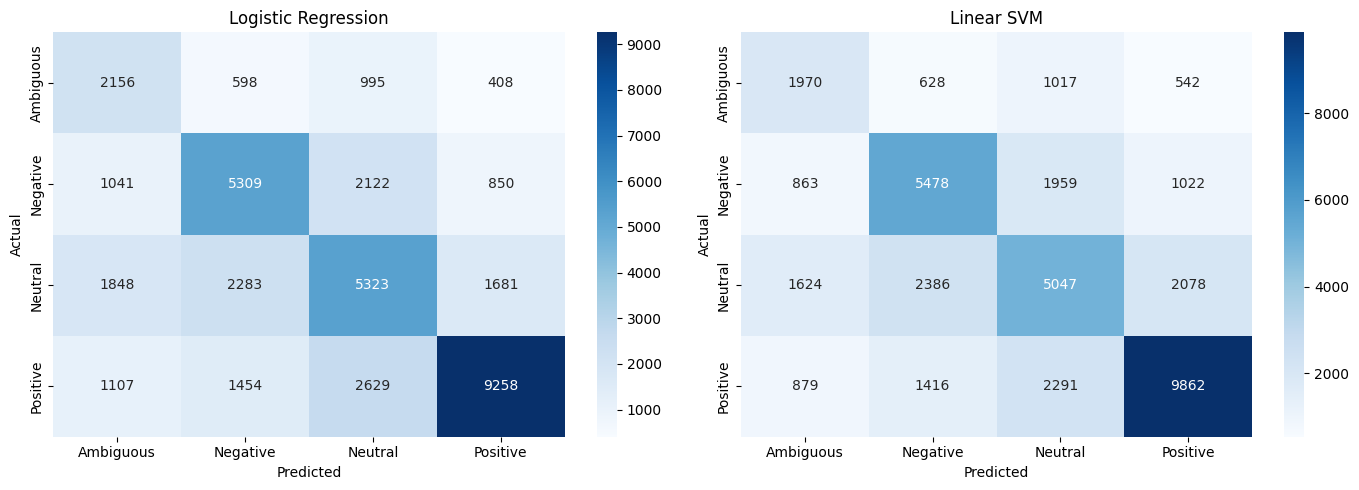

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, title, predictions in [
    (axes[0], "Logistic Regression", lr_pred),
    (axes[1], "Linear SVM", svm_pred)
]:
    matrix = confusion_matrix(y_test, predictions)
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 13. Plot Multiclass ROC Curves

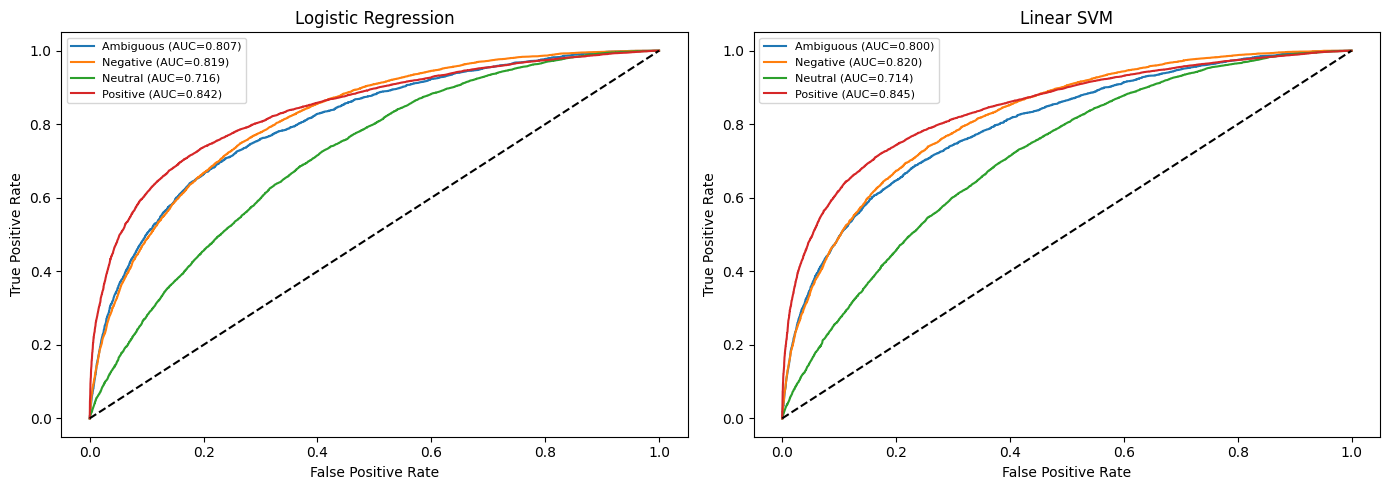

In [ ]:
y_test_binary = label_binarize(y_test, classes=np.arange(len(label_encoder.classes_)))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, title, scores in [
    (axes[0], "Logistic Regression", lr_scores),
    (axes[1], "Linear SVM", svm_scores)
]:
    for index, class_name in enumerate(label_encoder.classes_):
        fpr, tpr, _ = roc_curve(y_test_binary[:, index], scores[:, index])
        ax.plot(fpr, tpr, label=f"{class_name} (AUC={auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(title)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 14. Detailed Classification Reports

In [ ]:
print("LOGISTIC REGRESSION")
print(classification_report(y_test, lr_pred, target_names=label_encoder.classes_, zero_division=0))

print("LINEAR SVM")
print(classification_report(y_test, svm_pred, target_names=label_encoder.classes_, zero_division=0))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

   Ambiguous       0.35      0.52      0.42      4157
    Negative       0.55      0.57      0.56      9322
     Neutral       0.48      0.48      0.48     11135
    Positive       0.76      0.64      0.69     14448

    accuracy                           0.56     39062
   macro avg       0.54      0.55      0.54     39062
weighted avg       0.59      0.56      0.57     39062

LINEAR SVM
              precision    recall  f1-score   support

   Ambiguous       0.37      0.47      0.42      4157
    Negative       0.55      0.59      0.57      9322
     Neutral       0.49      0.45      0.47     11135
    Positive       0.73      0.68      0.71     14448

    accuracy                           0.57     39062
   macro avg       0.54      0.55      0.54     39062
weighted avg       0.58      0.57      0.58     39062



## 15. Saving

In [ ]:
if lr_metrics["F1 (Macro)"] >= svm_metrics["F1 (Macro)"]:
    best_model_name = "Logistic Regression"
    best_model = lr_model
else:
    best_model_name = "Linear SVM"
    best_model = svm_model

model_bundle = {
    "model": best_model,
    "vectorizer": tfidf,
    "label_encoder": label_encoder,
    "model_name": best_model_name,
    "target_definition": "Positive / Negative / Ambiguous / Neutral using the GoEmotions sentiment hierarchy",
    "emotion_groups": {
        "positive": POSITIVE,
        "negative": NEGATIVE,
        "ambiguous": AMBIGUOUS,
        "neutral": NEUTRAL
    },
    "cleaning_version": "light_v1"
}

joblib.dump(model_bundle, "goemotions_best_model.pkl", compress=3)
print("Selected model:", best_model_name)
print("Saved: goemotions_best_model.pkl")

Selected model: Linear SVM
Saved: goemotions_best_model.pkl


## 16. Reload and Test the Saved Model

In [ ]:
loaded_bundle = joblib.load("goemotions_best_model.pkl")

def predict_sentiment(text):
    cleaned = clean_text(text)
    features = loaded_bundle["vectorizer"].transform([cleaned])
    encoded_prediction = loaded_bundle["model"].predict(features)
    return loaded_bundle["label_encoder"].inverse_transform(encoded_prediction)[0]

print(predict_sentiment("I am extremely proud and happy about this result!"))
print(predict_sentiment("This is disappointing and makes me angry."))

Positive
Negative


## 17. Download the Model and Results

In [ ]:
comparison.to_csv("model_comparison.csv", index=False)

from google.colab import files
files.download("goemotions_best_model.pkl")
# files.download("model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>